# Figure 3: Properties of the international network of scientific citation preferences

This notebook reproduces Fig. 3: (A) odds ratios of the multinomial logit model, (B, C) positive and negative in-degree over time, (D) normalized entropy of the PageRank centrality, and (E) negative connection probability between communities.

It reads the processed data in the data folder (`path2data`) and can be run on its own.

In [1]:
import os
import json
import gzip
import itertools
from itertools import chain
import pandas as pd
import numpy as np
import networkx as nx

import scipy.sparse as spsparse
import scipy.stats as spstats

from statsmodels.stats.multitest import multipletests as holm
import statsmodels.api as sm

import matplotlib.pylab as plt
import matplotlib.gridspec as gridspec
import matplotlib.transforms as mtransforms
import seaborn as sns

from vizutils import pvalue2stars, table_row, make_multinomial_latex_table, logistic_coefficient_plot, logistic_odds_ratio_plot

import pyscisci.all as pyscisci

# set this path to where the OpenAlex database is stored
path2openalex = '/Users/hgt6rn/Documents/DataSets/OpenAlex'

# set this path to where the processed data (Source Data) is stored:
path2sourcedata = "Source Data"
# when the notebook is run from the code folder, the Source Data folder is one level up
if not os.path.exists(path2sourcedata):
    path2sourcedata = os.path.join("..", "Source Data")

# the processed input data are in the data folder, next to the Source Data folder
path2data = os.path.join(os.path.dirname(os.path.abspath(path2sourcedata)), 'data')

# the regenerated figures are saved in the figures folder
path2figures = os.path.join(os.path.dirname(os.path.abspath(path2sourcedata)), 'figures')
os.makedirs(path2figures, exist_ok=True)

Please install python-Levenshtein to take full advantage of the NLP tools. 
 pip install python-Levenshtein
Please install sparse_dot_topn to take full advantage of the NLP tools. 
 pip install sparse_dot_topn


/Users/psp2nq/anaconda3/lib/python3.11/site-packages/dask/dataframe/__init__.py:49: FutureWarning: 
Dask dataframe query planning is disabled because dask-expr is not installed.

You can install it with `pip install dask[dataframe]` or `conda install dask`.
This will raise in a future version.

  warnings.warn(msg, FutureWarning)


 # Analysis of the International Recognition Network

In [2]:
# lets focus on the citation without the same organization and self citations

country_auc_df = pd.read_csv(os.path.join(path2data, 'oa_countrycites_nosameorg_auc.csv.gz'))

country_auc_df = country_auc_df[country_auc_df['N']>=50]

country_auc_df['Zscore'] = (country_auc_df['AUC'] - 0.5)/np.sqrt(country_auc_df['Cov'])
# one-sided test in the direction of the observed preference: H1 is AUC > 0.5 (over-citation)
# when Z > 0, and AUC < 0.5 (under-citation) when Z < 0
country_auc_df['pvalue'] = spstats.norm.sf(np.abs(country_auc_df['Zscore'].values))

def reject_holm(pvalues):
    reject, pvalues, _, _ = holm(pvalues, alpha=0.01, method='hs', is_sorted=False, returnsorted=False)
    return reject
country_auc_df['Significant'] = country_auc_df.groupby('CitedYear')['pvalue'].transform(reject_holm)

net_auc = country_auc_df[country_auc_df['CitingCountry'] != country_auc_df['CitedCountry']].sort_values(by=['CitedYear', 'CitedCountry']).reset_index(drop=True)
net_auc = net_auc[net_auc['Significant']]
self_auc = country_auc_df[country_auc_df['CitingCountry'] == country_auc_df['CitedCountry']].sort_values(by=['CitedYear', 'CitedCountry']).reset_index(drop=True)
self_auc = self_auc[self_auc['Significant']]

syear, eyear = 1990, 2017
net_auc = net_auc[net_auc['CitedYear'] >= syear]
net_auc = net_auc[net_auc['CitedYear'] <= eyear]

comm2country = {0:['AE', 'BD', 'CN', 'CY', 'DZ', 'EG', 'ID', 'IN', 'IQ', 'IR', 'JO', 'KH', 'KR', 'KW', 'MA', 'MY', 'OM', 'PK', 'QA', 'SA', 'SG', 'TH', 'TN', 'TR', 'TW', 'VN'],
1:['AR', 'BN', 'BO', 'BR', 'BW', 'BY', 'CL', 'CM', 'CO', 'CR', 'GE', 'HK', 'HR', 'LU', 'MZ', 'NC', 'PA', 'PE', 'RU', 'SJ', 'ST', 'UY', 'VE'],
2:['AT', 'BE', 'CA', 'CZ', 'DE', 'DK', 'EE', 'ES', 'FI', 'FR', 'GR', 'HU', 'IE', 'IL', 'IS', 'IT', 'JP', 'MX', 'NL', 'NO', 'NP', 'NZ', 'PH', 'PL', 'PT', 'RO', 'SE', 'SI', 'SK'],
3:['AU', 'CH', 'GB', 'US'],
4:['BH', 'ET', 'GH', 'KE', 'MW', 'NG', 'TZ', 'UG', 'ZA', 'ZM', 'ZW']}

country2comm = {c:ci for ci,clist in comm2country.items() for c in clist}
poscountrylist = sorted(list(country2comm.keys()))

connected_countries = np.sort(np.unique(net_auc[net_auc['Zscore'] > 0][['CitingCountry', 'CitedCountry']].values.flatten()))

In [3]:
syear, eyear = 1990, 2017
net_auc = net_auc[net_auc['CitedYear'] >= syear]
net_auc = net_auc[net_auc['CitedYear'] <= eyear]
cumulative_net = net_auc.sort_values('CitedYear').drop_duplicates(subset=['CitingCountry', 'CitedCountry'], keep='last')

cumulative_net['SourceCommunity'] = cumulative_net['CitingCountry'].map(country2comm)
cumulative_net['TargetCommunity'] = cumulative_net['CitedCountry'].map(country2comm)
cumulative_net['InterCommunity'] = cumulative_net['SourceCommunity'] != cumulative_net['TargetCommunity']

print(cumulative_net.shape, "edges")
cum_connected_countries = np.sort(np.unique(cumulative_net[['CitingCountry', 'CitedCountry']].values.flatten()))
print(cum_connected_countries.shape, "countries")
pcumnet = cumulative_net[cumulative_net['Zscore'] > 0]
print(pcumnet.shape, "positive edges")
print(pcumnet['CitedCountry'].value_counts())
ncumnet = cumulative_net[cumulative_net['Zscore'] < 0]
print(ncumnet.shape, "negative edges")
print(ncumnet['CitedCountry'].value_counts())

(2007, 12) edges
(147,) countries
(536, 12) positive edges
CitedCountry
CH    36
GB    31
NL    22
DE    22
BE    20
      ..
RU     1
CR     1
HR     1
PE     1
MA     1
Name: count, Length: 81, dtype: int64
(1471, 12) negative edges
CitedCountry
CN    86
JP    63
IR    48
BR    45
TR    45
      ..
CG     1
TJ     1
PH     1
HK     1
GD     1
Name: count, Length: 126, dtype: int64


In [4]:
countryprod = pd.read_csv(os.path.join(path2data, 'oa_country_productivity.csv'))
syear = 1990
eyear = 2017

countryprod = countryprod[countryprod['Year'] >= syear]
countryprod = countryprod[countryprod['Year'] <= eyear].reset_index(drop=True)
print(countryprod.shape)

(5869, 5)


In [5]:
pin = []
nin = []
pout = []
nout = []

for y in np.arange(syear, eyear + 1):
    ysub = net_auc[net_auc['CitedYear'] <= y].drop_duplicates(subset=['CitingCountry', 'CitedCountry'], keep='last')
    
    ypin = ysub[ysub['Zscore'] > 0].groupby('CitedCountry', as_index=False)['CitingCountry'].nunique()
    ypin = ypin.rename(columns={'CitedCountry':'Country', 'CitingCountry':'PositiveInDegree'})
    ypin['Year'] = y
    pin.append(ypin)
    
    ynin = ysub[ysub['Zscore'] < 0].groupby('CitedCountry', as_index=False)['CitingCountry'].nunique()
    ynin = ynin.rename(columns={'CitedCountry':'Country', 'CitingCountry':'NegativeInDegree'})
    ynin['Year'] = y
    nin.append(ynin)
    
    ypout = ysub[ysub['Zscore'] > 0].groupby('CitingCountry', as_index=False)['CitedCountry'].nunique()
    ypout = ypout.rename(columns={'CitingCountry':'Country', 'CitedCountry':'PositiveOutDegree'})
    ypout['Year'] = y
    pout.append(ypout)
    
    ynout = ysub[ysub['Zscore'] < 0].groupby('CitingCountry', as_index=False)['CitedCountry'].nunique()
    ynout = ynout.rename(columns={'CitingCountry':'Country', 'CitedCountry':'NegativeOutDegree'})
    ynout['Year'] = y
    nout.append(ynout)
    

pin = pd.concat(pin)    
countryprod = countryprod.merge(pin, how='left', on=['Country', 'Year']).fillna(0)
nin = pd.concat(nin)    
countryprod = countryprod.merge(nin, how='left', on=['Country', 'Year']).fillna(0)
pout = pd.concat(pout)    
countryprod = countryprod.merge(pout, how='left', on=['Country', 'Year']).fillna(0)
nout = pd.concat(nout)    
countryprod = countryprod.merge(nout, how='left', on=['Country', 'Year']).fillna(0)
countryprod

,Year,Country,NumPub,TopJournal,FracTop,PositiveInDegree,NegativeInDegree,PositiveOutDegree,NegativeOutDegree
0,1990.0,AD,1,0.0,0.000000,0.0,0.0,0.0,0.0
1,1990.0,AE,109,73.0,0.669725,0.0,0.0,0.0,0.0
2,1990.0,AF,2,1.0,0.500000,0.0,0.0,0.0,0.0
3,1990.0,AL,34,10.0,0.294118,0.0,0.0,0.0,0.0
4,1990.0,AM,212,96.0,0.452830,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...
5864,2017.0,XK,631,84.0,0.133122,0.0,2.0,0.0,2.0
5865,2017.0,YE,403,106.0,0.263027,0.0,1.0,0.0,0.0
5866,2017.0,ZA,23661,8606.0,0.363721,11.0,11.0,14.0,16.0
5867,2017.0,ZM,702,306.0,0.435897,1.0,2.0,1.0,4.0


In [6]:
syear, eyear = 1990, 2017

yent = np.zeros((eyear-syear + 1))

for y in range(syear, eyear + 1):
    
    ysub = net_auc[net_auc['CitedYear'] <= y].drop_duplicates(subset=['CitingCountry', 'CitedCountry'], keep='last')
    posnet = ysub[ysub['Zscore']>0]

    usednodes = np.sort(np.unique(posnet[['CitingCountry', 'CitedCountry']].values.flatten()))
    
    ypnet = nx.DiGraph()
    ypnet.add_nodes_from(usednodes)
    ypnet.add_edges_from([(s, t) for s,t in posnet[['CitingCountry', 'CitedCountry']].values])
    
    prdict = nx.pagerank(ypnet, alpha=0.85)
    pr = np.array([prdict[v] for v in ypnet.nodes()])
    yent[y-syear] = spstats.entropy(pr/pr.sum())/np.log2(len(ypnet))
    

## Probability of connection within / between communities

In [7]:


renumber_blocks = {3:0, 2:1,1:4,0:2,4:3}

v2com = np.array([renumber_blocks[country2comm[c]] for c in poscountrylist])

fullcnames, fullcsizes = np.unique(v2com, return_counts=True)
print(fullcnames, fullcsizes)
nc = fullcnames.shape[0]

pblock_matrix = np.zeros((eyear - syear + 1, nc,nc))
nblock_matrix = np.zeros((eyear - syear + 1, nc,nc))

for y in range(syear, eyear + 1):
    
    ysub = net_auc[net_auc['CitedYear'] <= y].drop_duplicates(subset=['CitingCountry', 'CitedCountry'], keep='last')
    posnet = ysub[ysub['Zscore']>0]
    
    usednodes = np.sort(np.unique(posnet[['CitingCountry', 'CitedCountry']].values.flatten()))
    yv2com = v2com[pyscisci.isin_sorted(connected_countries, usednodes)]
    
    pnet = nx.DiGraph()
    pnet.add_nodes_from(usednodes)
    pnet.add_edges_from([(s, t) for s,t in posnet[['CitingCountry', 'CitedCountry']].values])
    padjmat = nx.to_numpy_array(pnet, nodelist = usednodes)
    
    negnet = ysub[ysub['Zscore']<0]
    nnet = nx.DiGraph()
    nnet.add_nodes_from(usednodes)
    nnet.add_edges_from([(s, t) for s,t in negnet[['CitingCountry', 'CitedCountry']].values])
    nadjmat = nx.to_numpy_array(nnet, nodelist = usednodes)
    
    cnames, csizes = np.unique(yv2com, return_counts=True)
    csizes = dict(zip(cnames, csizes))
    #print(y, yv2com.shape, padjmat.shape, nadjmat.shape)
    #print(cnames, csizes )
    
    for ic in cnames:
        for jc in cnames:
            #denom = csizes[ic]*csizes[jc]
            denom = fullcsizes[ic]*fullcsizes[jc]
            pblock_matrix[y-syear, ic, jc] = padjmat[yv2com==ic][:,yv2com==jc].sum()/denom
            nblock_matrix[y-syear, ic, jc] = nadjmat[yv2com==ic][:,yv2com==jc].sum()/denom

    #print(nblock_matrix)

[0 1 2 3 4] [ 4 29 26 11 23]


# Multinomial Link Prediction

In [8]:
panel_data = pd.read_csv(os.path.join(path2data, 'link_prediction_panel_data_1990_2017.csv.gz'))


net_panel = panel_data.merge(net_auc.rename(columns={'CitingCountry':'oCountry', 'CitedCountry':'tCountry','CitedYear':'year'}), 
                           how='left', on=['oCountry','tCountry','year'])

net_panel['edge_preference'] = 1 + (net_panel['Zscore'] < 0).astype(int)
net_panel.loc[net_panel['Significant'].isnull(), 'edge_preference'] = 0

# the citation preferences cover 1990-2017, so the panel rows of later years are not used
net_panel = net_panel[(net_panel['year'] >= syear) & (net_panel['year'] <= eyear)].reset_index(drop=True)

net_panel['edge_preference'].unique()

dummy_years=['year_'+str(i) for i in range(syear + 1, eyear + 1)]

all_dummies=['comlang_off','SameContinent']+dummy_years

net_panel_with_dummies = pd.get_dummies(net_panel, columns=['year'], drop_first=True)
net_panel_with_dummies[dummy_years] = net_panel_with_dummies[dummy_years].astype(int)



v1=['oGDP_PCAP','tGDP_PCAP', 'oPop','tPop']
v2=['PhysicalDistance','SameContinent']
v3=['comlang_off','TopicSimilarity']
v4=['cumulative_laws']
v5=['CollabStrength']
v6=['oTopFrac','tTopFrac']


all_model_features = v1 + v2 + v3 + v4 + v5 + v6

# continuous variables are standardized once over the 1990-2017 panel, so all models share the same scale
for c in all_model_features:
    if net_panel_with_dummies[c].nunique() > 2:
        net_panel_with_dummies[c] = (net_panel_with_dummies[c] - net_panel_with_dummies[c].mean())/net_panel_with_dummies[c].std()

exog_var_sets = [v1+dummy_years,v2,v3,v4,v5,v6]
dep_var = "edge_preference"

Nmodels = len(exog_var_sets)

fit_models = []
for icol in range(Nmodels):
    exog_vars = list(chain.from_iterable(exog_var_sets[:(icol+1)]))
    X = net_panel_with_dummies[exog_vars + [dep_var]].dropna().reset_index(drop=True)

    Y = X[dep_var]
    X = sm.add_constant(X[exog_vars])

    model = sm.MNLogit(Y, X).fit()
    fit_models.append(model)
    

Optimization terminated successfully.
         Current function value: 0.039011
         Iterations 12
Optimization terminated successfully.
         Current function value: 0.039781
         Iterations 12
Optimization terminated successfully.
         Current function value: 0.038455
         Iterations 13
Optimization terminated successfully.
         Current function value: 0.038375
         Iterations 13
Optimization terminated successfully.
         Current function value: 0.036143
         Iterations 13
Optimization terminated successfully.
         Current function value: 0.034350
         Iterations 13


In [9]:
def summary_table(model,ycat,ycat_name):
    
    dfpo=model.params.reset_index().rename(columns={'index':'item'})
    dfc1=dfpo[['item',ycat-1]].rename(columns={ycat-1:'risk'})
    
    dfpv=model.pvalues.reset_index().rename(columns={'index':'item'})
    dfpv=dfpv[['item',ycat-1]].rename(columns={ycat-1:'pvalues'})

    df1=dfc1.merge(dfpv,how='left',on='item')
    
    dfcon1=model.conf_int().loc[str(ycat)].reset_index().rename(columns={'index':'item','lower':0,'upper':1})
    df2=df1.merge(dfcon1,how='left',on='item')

    df2['strf']=ycat_name

    return df2

dfc1=summary_table(fit_models[-1],1,'Positive recognition')
dfc2=summary_table(fit_models[-1],2,'Negative recognition')

dfs=pd.concat([dfc1,dfc2])

# the odds ratios and labels of Fig. 3A
for c in ['risk', 0, 1]:
    dfs['odds_' + str(c)] = np.exp(dfs[c]) 

namedict = {'const':'Intercept', 'oTopFrac':'Origin top journal fraction', 'tTopFrac':'Target top journal fraction', 'oGDP_PCAP':'Log origin GDP per capita', 'oPop':'Log origin population','tPop':'Log target population',
           'tGDP_PCAP':'Log target GDP per capita', 'PhysicalDistance': 'Physical distance', 'TopicSimilarity':'Field similarity', 
            'comlang_off':'Same official language', 'CollabStrength':'Log collaboration strength','SameContinent':'Same continent',
           'cumulative_laws':'Bilateral research agreements'}

dfs.replace(namedict,inplace=True)

dfs['category']=dfs['item']

#drop the year fixed effect rows
dfs = dfs[~dfs['item'].str.contains('year')].reset_index(drop=True)

df1 = dfs[dfs["strf"] == "Positive recognition"].reset_index(drop=True)
df2 = dfs[dfs["strf"] == "Negative recognition"].reset_index(drop=True)

df1['xerror']=df1[1]-df1['risk']
df2['xerror']=df2[1]-df2['risk']

df1=df1[df1['item']!='Intercept']
df2=df2[df2['item']!='Intercept']

#dfs

## Figure 3

/Users/psp2nq/anaconda3/lib/python3.11/site-packages/matplotlib/cbook.py:1699: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return math.isfinite(val)
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


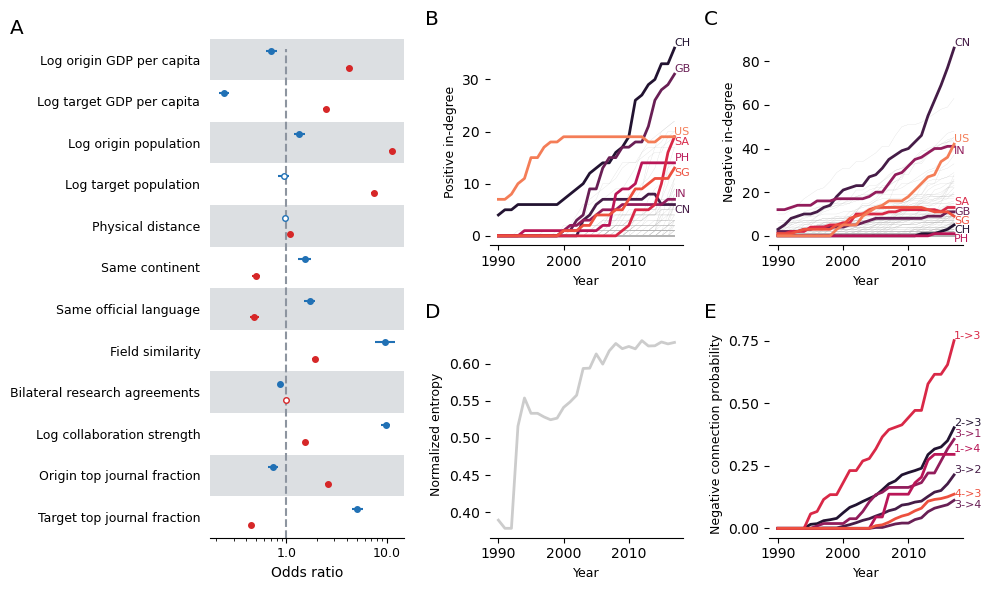

In [10]:
countries2highlight = sorted(['US', 'CH', 'GB', 'PH', 'SA', 'SG', 'CN', 'IN'])

lblsize = 9

colours=['#8D95A0','#2171b5','#DA6437']
colours=['#8D95A0','#2171b5',sns.color_palette()[3]]


layout = [
    ["A", "B", "C"],
    ["A", "D", "E"]
]

fig, axd = plt.subplot_mosaic(layout, figsize=(10,6))

logistic_odds_ratio_plot(df1, df2, colours, ax=axd["A"])

label = "A"
trans = mtransforms.ScaledTranslation(-2, 7/72, fig.dpi_scale_trans)
axd[label].text(0.0, 1.0, label, transform=axd[label].transAxes + trans,
                   fontsize='x-large', va='center')

comm2color = {0:"#257BA0", 1:"#6AB8AB", 2:"#D65451", 3:"#FFE000", 4:"#FF9400"}

for c in countryprod['Country'].unique():
    countrysub = countryprod[countryprod['Country'] == c].sort_values('Year')
    
    if c in countries2highlight:
        color = sns.color_palette("rocket", n_colors=len(countries2highlight) + 2)[countries2highlight.index(c)]
        axd["B"].plot(countrysub['Year'].values, countrysub['PositiveInDegree'].values, color=color, lw=2, zorder=10)
        axd["C"].plot(countrysub['Year'].values, countrysub['NegativeInDegree'].values, color=color, lw=2, zorder=10)
        
        if c in ['CN', 'SA', 'SG']:
            axd["B"].text(s=c, x=countrysub['Year'].values[-1], y=countrysub['PositiveInDegree'].values[-1],
                    ha='left', va='top', color=color, fontsize=8)
        else:
            axd["B"].text(s=c, x=countrysub['Year'].values[-1], y=countrysub['PositiveInDegree'].values[-1],
                    ha='left', va='bottom', color=color, fontsize=8)
        
        if c in ['IN', 'PH', 'CH', 'SG']:
            axd["C"].text(s=c, x=countrysub['Year'].values[-1], y=countrysub['NegativeInDegree'].values[-1],
                    ha='left', va='top', color=color, fontsize=8)
        elif c in ['GB']:
            axd["C"].text(s=c, x=countrysub['Year'].values[-1], y=countrysub['NegativeInDegree'].values[-1],
                    ha='left', va='center', color=color, fontsize=8)
        else:
            axd["C"].text(s=c, x=countrysub['Year'].values[-1], y=countrysub['NegativeInDegree'].values[-1],
                    ha='left', va='bottom', color=color, fontsize=8)
    else:    
        axd["B"].plot(countrysub['Year'].values, countrysub['PositiveInDegree'].values, color='0.7', lw=0.1, zorder=1)
        axd["C"].plot(countrysub['Year'].values, countrysub['NegativeInDegree'].values, color='0.7', lw=0.1, zorder=1)

axd["B"].set_ylabel('Positive in-degree', fontsize=lblsize)
axd["C"].set_ylabel('Negative in-degree', fontsize=lblsize)
axd["D"].set_ylabel('Normalized entropy', fontsize=lblsize)
axd["E"].set_ylabel('Negative connection probability', fontsize=lblsize)

#axd["E"].axis('off')

axd['D'].plot(np.arange(1990, 2018), yent, color='0.8', lw=2)

for i,(ic,jc) in enumerate([(1,2), (2,1), (2,3),  (2,0),(0,3), (0,2), (3,2)]):
    color=sns.color_palette("rocket", n_colors=len(countries2highlight) + 2)[i]
    axd["E"].plot(np.arange(1990, 2018), nblock_matrix[:,ic,jc], lw=2, color=color)
    
    if (ic,jc) in [(3,0),  (2,3)]:
        va = 'top'
    elif (ic,jc) in [(3,2), (3,0)]:
        va = 'center'
    else:
        va = 'bottom'
    axd["E"].text(s=str(ic+1)+"->"+str(jc+1), x=2017, y=nblock_matrix[-1,ic,jc], ha='left', va=va, 
                  color=color, fontsize=8)

#axd["E"].set_yticks([0, 0.25, 0.5,0.75])
axd["E"].set_yticks([0, 0.25, 0.5,0.75])


for label in ['B', "C", "D", "E"]:
    axd[label].set_xlabel('Year', fontsize=lblsize)
    # label physical distance in and down:
    trans = mtransforms.ScaledTranslation(-0.65, 7/72, fig.dpi_scale_trans)
    axd[label].text(0.0, 1.0, label, transform=axd[label].transAxes + trans,
                   fontsize='x-large', va='bottom')#, xx-small, x-small, small, medium, large, x-large, xx-large, larger, smaller
plt.tight_layout()

plt.savefig(os.path.join(path2figures, 'Fig3_networkfeatures.pdf'))

plt.show()

## Statistical tests reported in the main text

Trend tests for Fig. 3D and 3E and the chi-squared test of positive and negative edges between communities.

In [11]:
# D) trend of the normalized entropy over the years (Kendall's tau with year)
years = np.arange(syear, eyear + 1)
tau, pval = spstats.kendalltau(years, yent)
print("Normalized entropy: Kendall's tau = {:.2f}, p = {:.3g}, n = {} years".format(tau, pval, len(years)))

# E) trend of the negative connection probability for each community pair shown in Fig. 3E
pairs_E = [(1,2), (2,1), (2,3), (2,0), (0,3), (0,2), (3,2)]
for ic, jc in pairs_E:
    tau, pval = spstats.kendalltau(years, nblock_matrix[:, ic, jc])
    print("Community {}->{}: Kendall's tau = {:.2f}, p = {:.3g}".format(ic + 1, jc + 1, tau, pval))

# pooled over the community pairs shown in Fig. 3E
pooled_years = np.concatenate([years for _ in pairs_E])
pooled_prob = np.concatenate([nblock_matrix[:, ic, jc] for ic, jc in pairs_E])
tau, pval = spstats.kendalltau(pooled_years, pooled_prob)
print("Pooled: Kendall's tau = {:.2f}, p = {:.3g}, n = {}".format(tau, pval, len(pooled_years)))

# positive vs negative edges between communities in the cumulative network
# (countries outside the five communities count as between communities, as in the 34% and 86% in the text)
sign = np.where(cumulative_net['Zscore'] > 0, 'Positive', 'Negative')
crosstab = pd.crosstab(sign, cumulative_net['InterCommunity'])
print(crosstab)
print((crosstab[True]/crosstab.sum(axis=1)).round(3))
chi2, pval, dof, _ = spstats.chi2_contingency(crosstab.values, correction=False)
cramer_v = np.sqrt(chi2/crosstab.values.sum())
print("chi2({}) = {:.1f}, p = {:.3g}, Cramer's V = {:.2f}, n = {}".format(dof, chi2, pval, cramer_v, crosstab.values.sum()))


Normalized entropy: Kendall's tau = 0.82, p = 1.02e-09, n = 28 years
Community 2->3: Kendall's tau = 0.99, p = 3.01e-13
Community 3->2: Kendall's tau = 0.97, p = 1.66e-12
Community 3->4: Kendall's tau = 0.85, p = 5.15e-09
Community 3->1: Kendall's tau = 0.96, p = 3.4e-12
Community 1->4: Kendall's tau = 0.83, p = 1.84e-08
Community 1->3: Kendall's tau = 0.98, p = 5.18e-13
Community 4->3: Kendall's tau = 0.85, p = 4.04e-09
Pooled: Kendall's tau = 0.63, p = 7.89e-35, n = 196
InterCommunity  False  True 
row_0                       
Negative          203   1268
Positive          353    183
row_0
Negative    0.862
Positive    0.341
dtype: float64
chi2(1) = 531.6, p = 1.29e-117, Cramer's V = 0.51, n = 2007


## Source Data for Figure 3

The data plotted in each panel, written to `Source Data/SourceData_3_Fig3.xlsx`.

In [12]:
# the Source Data helpers (sourcedatautils.py, in the code folder like vizutils.py)
from sourcedatautils import write_source_data, edge_columns

title = 'Figure 3: Properties of the international network of scientific citation preferences.'
description = ('A) Odds ratios of the multinomial logit model with temporal fixed-effects (Model 6 of Supplementary '
               'Table 6; continuous variables standardized once over the 1990-2017 country-pair panel) predicting a '
               'positive or negative citation preference compared to no preference, with 95% confidence intervals; '
               'points are statistically significant at p <= 0.05. '
               'B, C) Positive and negative in-degree of each country in the cumulative network up to each year; '
               'highlighted countries are drawn in colour. '
               'D) Normalized entropy of the PageRank centrality of the cumulative positive network. '
               'E) Probability of a negative edge from a country in the source community to a country in the target '
               'community (communities labelled 1-5). ')

# A) the coefficients of the final model
coefs = []
for outcome, df in [('Positive', df1), ('Negative', df2)]:
    df = df[['item', 'odds_risk', 'odds_0', 'odds_1', 'risk', 'pvalues']].copy()
    df.columns = ['Variable', 'Odds ratio', 'CI lower (95%)', 'CI upper (95%)', 'Coefficient', 'p-value']
    df.insert(1, 'Citation preference', outcome)
    df['Significant (p <= 0.05)'] = df['p-value'] <= 0.05
    coefs.append(df)
coefs = pd.concat(coefs, ignore_index=True)

# B, C) the yearly in-degree
indegree = countryprod[['Year', 'Country', 'PositiveInDegree', 'NegativeInDegree']].copy()
indegree['Year'] = indegree['Year'].astype(int)
indegree[['PositiveInDegree', 'NegativeInDegree']] = indegree[['PositiveInDegree', 'NegativeInDegree']].astype(int)
indegree['Highlighted'] = indegree['Country'].isin(countries2highlight)
indegree = indegree.rename(columns={'PositiveInDegree':'Positive in-degree', 'NegativeInDegree':'Negative in-degree'})
indegree = indegree.sort_values(['Country', 'Year']).reset_index(drop=True)

# D) the normalized entropy
entropy = pd.DataFrame({'Year':np.arange(syear, eyear + 1), 'Normalized entropy':yent})

# E) the negative connection probability for the community pairs in the figure
negprob = pd.DataFrame({'Year':np.arange(syear, eyear + 1)})
for ic, jc in [(1,2), (2,1), (2,3), (2,0), (0,3), (0,2), (3,2)]:
    negprob[str(ic+1) + '->' + str(jc+1)] = nblock_matrix[:, ic, jc]



tables = [('A', 'A) Odds ratios of the positive and negative citation preference (Model 6).', coefs),
          ('B and C', 'B, C) Positive and negative in-degree of each country by year.', indegree),
          ('D', 'D) Normalized entropy of the PageRank centrality by year.', entropy),
          ('E', 'E) Negative connection probability between communities (source->target) by year.', negprob)]

write_source_data('SourceData_3_Fig3.xlsx', title, description, tables)



wrote /Users/psp2nq/Documents/NationalBiasCode/Source Data/SourceData_3_Fig3.xlsx
wrote /Users/psp2nq/Documents/NationalBiasCode/Source Data/README.txt
